# Dataset preparation for YOLOv8 model fine-tuning

## Combining Roboflow datasets

In [ ]:
from roboflow import Roboflow

In [1]:
# 1808 dataset

rf = Roboflow(api_key="5XEfDZRIIjMqbazGL6nS")
project = rf.workspace("bachelor-d6dut").project("car-detection-bachelor")
version = project.version(3)
dataset = version.download("yolov8")
                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Car-detection-bachelor-3 in yolov8:: 100%|██████████| 3628/3628 [00:03<00:00, 909.28it/s] 


In [2]:
# 998 dataset

rf = Roboflow(api_key="zolhGuu1snsuy5zeAJsS")
project = rf.workspace("bachelor-jvyhh").project("superstar-car-project")
version = project.version(2)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to superstar-car-project-2 in yolov8:: 100%|██████████| 2002/2002 [00:02<00:00, 724.41it/s] 


In [4]:
# 599 dataset
rf = Roboflow(api_key="VcIz6aIo01dcvjkU8AMO")
project = rf.workspace("labeling-2").project("labeling-2-hoswc")
version = project.version(2)
dataset = version.download("yolov8")           

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to labeling-2-2 in yolov8:: 100%|██████████| 1204/1204 [00:00<00:00, 1298.76it/s]


In [5]:
# 707 dataset
rf = Roboflow(api_key="uxiGJrqUcSW3MVh0ONYd")
project = rf.workspace("poopy-epswg").project("my-first-project-wajtf")
version = project.version(3)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to My-First-Project-3 in yolov8:: 100%|██████████| 1420/1420 [00:01<00:00, 878.02it/s]


In [10]:
# 796 dataset
rf = Roboflow(api_key="uxiGJrqUcSW3MVh0ONYd")
project = rf.workspace("poopy-epswg").project("pooper")
version = project.version(1)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to pooper-1 in yolov8:: 100%|██████████| 1598/1598 [00:01<00:00, 992.62it/s]


In [6]:
import os
import shutil
import random

## Merging the datasets

In [ ]:

datasets_folder = "datasets"

merged = "merged_dataset"

os.makedirs(os.path.join(merged, "images"), exist_ok=True)
os.makedirs(os.path.join(merged, "labels"), exist_ok=True)

dataset_paths = [
    os.path.join(datasets_folder, name)
    for name in os.listdir(datasets_folder)
    if os.path.isdir(os.path.join(datasets_folder, name))
]

def copy_dataset(source_folder, merged_folder):
    for split in ['train', 'valid', 'test']:
        img_dir = os.path.join(source_folder, split, 'images')
        lbl_dir = os.path.join(source_folder, split, 'labels')
        if os.path.exists(img_dir):
            for file in os.listdir(img_dir):
                shutil.copy(os.path.join(img_dir, file), os.path.join(merged_folder, 'images', file))
        if os.path.exists(lbl_dir):
            for file in os.listdir(lbl_dir):
                shutil.copy(os.path.join(lbl_dir, file), os.path.join(merged_folder, 'labels', file))

for dataset in dataset_paths:
    copy_dataset(dataset, merged)

## Split into train/val/test

In [ ]:
image_files = os.listdir(os.path.join(merged, "images"))
random.shuffle(image_files)

total = len(image_files)
train_split = int(0.7 * total)
val_split = int(0.85 * total)  

train_files = image_files[:train_split]
val_files = image_files[train_split:val_split]
test_files = image_files[val_split:]

for split in ['train', 'valid', 'test']:
    os.makedirs(os.path.join(merged, split, 'images'), exist_ok=True)
    os.makedirs(os.path.join(merged, split, 'labels'), exist_ok=True)

def move_files(file_list, split):
    for file in file_list:
        img_src = os.path.join(merged, "images", file)
        lbl_src = os.path.join(merged, "labels", file.rsplit('.', 1)[0] + '.txt') 
        
        img_dst = os.path.join(merged, split, "images", file)
        lbl_dst = os.path.join(merged, split, "labels", file.rsplit('.', 1)[0] + '.txt')

        if os.path.exists(img_src):
            shutil.move(img_src, img_dst)
        if os.path.exists(lbl_src):
            shutil.move(lbl_src, lbl_dst)

move_files(train_files, "train")
move_files(val_files, "valid")
move_files(test_files, "test")

shutil.rmtree(os.path.join(merged, "images"))
shutil.rmtree(os.path.join(merged, "labels"))

print("Dataset merged and split: 70% train, 15% valid, 15% test.")


Dataset merged and split: 70% train, 15% valid, 15% test.


## Balance between images with 0 items vs >0

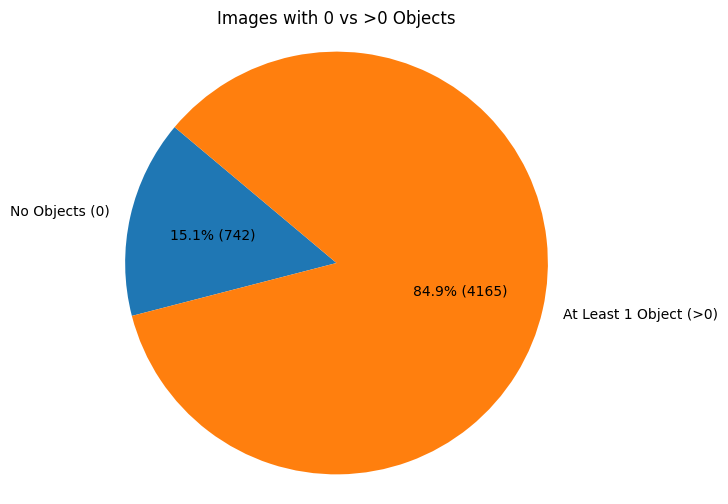

In [ ]:
import matplotlib.pyplot as plt

label_dirs = [
    "merged_dataset/train/labels",
    "merged_dataset/valid/labels",
    "merged_dataset/test/labels",
]

object_counts = []

for label_dir in label_dirs:
    if os.path.exists(label_dir):
        for label_file in os.listdir(label_dir):
            if label_file.endswith(".txt"):
                label_path = os.path.join(label_dir, label_file)
                with open(label_path, "r") as f:
                    lines = f.readlines()
                    object_counts.append(len(lines))  

zero_objects = object_counts.count(0)
nonzero_objects = len(object_counts) - zero_objects

labels = ['No Objects (0)', 'At Least 1 Object (>0)']
sizes = [zero_objects, nonzero_objects]

plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    labels=labels,
    autopct=lambda p: f'{p:.1f}% ({int(p/100*sum(sizes))})',
    startangle=140
)
plt.title("Images with 0 vs >0 Objects")
plt.axis('equal')
plt.show()
